# Training vs test deployments

Map of every deployment in the DORI v2 annotations (`annotations_bgcap10000.csv`, the pretraining comparison's dataset):
- **test** (orange): the three held-out fine-tune / evaluation sites -- DORI VENUS Strait of Georgia, Lime Kiln, Tekteksen (East Point, Saturna)
- **training** (blue): every other deployment (the source data A / B are pretrained on)

Marker area scales with the number of annotation rows (after `classes_to_drop`).

Only the DORI / ONC rows carry `lat` / `lon` (and not all of them: the rest are placed by hydrophone ID where it is unambiguous); the DCLDE 2027 datasets don't, so they use `SITE_COORDS` below.
`exact` = from provider metadata (UAF `Hydrophone-locations.xlsx`) or a matching DORI row; `approx` = the named site's published location, worth checking before this goes in a paper.

In [1]:
import folium
import numpy as np
import pandas as pd
from branca.element import Element

ANNOTATIONS = "/home/noah/HALLO_encoder_collection/data_raw/DORI/20261022_190549/annotations_bgcap10000.csv"
CLASSES_TO_DROP = ["NRKW", "OKW", "KW_und", "SAR"]  # configs/pretraining_comparison/00_base.yaml
TEST_SITES = ["DORI VENUS (Strait of Georgia)", "LimeKiln", "Tekteksen"]
UNUSED_HOLDOUT = ["DORI VENUS (Saanich)"]  # in test_holdout_values, so not training, but not a test site either: not mapped
COLORS = {"test": "#e8590c", "training": "#1c7ed6"}

In [2]:
annotations = pd.read_csv(ANNOTATIONS, low_memory=False, usecols=["Dataset", "Provider", "ClassSpecies", "Soundfile", "lat", "lon"])
annotations = annotations[~annotations.ClassSpecies.isin(CLASSES_TO_DROP)].assign(Dataset=lambda d: d.Dataset.str.strip())  # one 'DORI ' row
annotations = annotations[~annotations.Dataset.isin(UNUSED_HOLDOUT)]

# DORI rows without lat / lon: take the location of the same hydrophone (filename prefix) in the same dataset, when it has
# exactly one; the rest stay unplaced and are left off the map (counted below)
annotations["device"] = annotations.Soundfile.str.split(r"[_.]").str[0]
device_site = (annotations.dropna(subset=["lat"]).assign(la=lambda d: d.lat.round(2), lo=lambda d: d.lon.round(2))
               .groupby(["Dataset", "device"]).agg(n_sites=("la", lambda s: len(set(zip(s, annotations.loc[s.index, "lon"].round(2))))),
                                                   lat_fill=("lat", "mean"), lon_fill=("lon", "mean")))
device_site = device_site[device_site.n_sites == 1].drop(columns="n_sites")
annotations = annotations.join(device_site, on=["Dataset", "device"])
fill = annotations.lat.isna() & annotations.Dataset.str.startswith("DORI")
annotations.loc[fill, ["lat", "lon"]] = annotations.loc[fill, ["lat_fill", "lon_fill"]].to_numpy()
unplaced = fill & annotations.lat.isna()
print("DORI rows placed by hydrophone:", int((fill & ~unplaced).sum()), " unplaced (not mapped):",
      annotations[unplaced].groupby("Dataset").size().to_dict())
annotations = annotations[~unplaced]
annotations.groupby(["Dataset", "Provider"]).agg(rows=("Dataset", "size"), with_latlon=("lat", "count"))

DORI rows placed by hydrophone: 12273  unplaced (not mapped): {'DORI': 56, 'DORI VENUS (Strait of Georgia)': 5428}


,,rows,with_latlon
Dataset,Provider,,
BarkleyCanyon,ONC,30795,0
BoundaryPass,JASCO_VFPA,3653,0
CarmanahPt,DFO_WDLP,12184,0
Cpe_Elz,SIO,15581,0
DORI,ONC,2094,2094
DORI VENUS (Strait of Georgia),ONC,17124,17124
Field_HTI,UAF_NGOS,771,0
Field_SondTrap,UAF_NGOS,558,0
HE_67391498,UAF_NGOS,148,0


In [3]:
# dataset -> (lat, lon, source) for the datasets whose rows have no lat / lon
SITE_COORDS = {
    # held-out test sites
    "LimeKiln": (48.5158, -123.1527, "approx: Lime Kiln lighthouse, San Juan Island"),
    "Tekteksen": (48.7835, -123.0446, "approx: East Point, Saturna Island"),
    # UAF (Alaska) -- exact, uaf/metadata/Hydrophone-locations.xlsx (deg + decimal min)
    "HE_67391498": (60 + 18.45 / 60, -(146 + 58.38 / 60), "exact: Hinchinbrook Entrance"),
    "HE_67424266": (60 + 18.45 / 60, -(146 + 58.38 / 60), "exact: Hinchinbrook Entrance"),
    "KB_5354": (59 + 52.60 / 60, -(151 + 50.91 / 60), "exact: Kachemak Bay"),
    "KB_67383303": (59 + 52.60 / 60, -(151 + 50.91 / 60), "exact: Kachemak Bay"),
    "KB_67424266": (59 + 52.60 / 60, -(151 + 50.91 / 60), "exact: Kachemak Bay"),
    "MS_5360": (60 + 10.51 / 60, -(147 + 49.09 / 60), "exact: Montague Strait"),
    "MS_671879205": (60 + 10.51 / 60, -(147 + 49.09 / 60), "exact: Montague Strait"),
    "MS_6897": (60 + 10.51 / 60, -(147 + 49.09 / 60), "exact: Montague Strait"),
    "RB_335826997": (59 + 43.96 / 60, -(149 + 31.94 / 60), "exact: Resurrection Bay"),
    "RB_67424266": (59 + 43.96 / 60, -(149 + 31.94 / 60), "exact: Resurrection Bay"),
    "Field_HTI": (60.0, -148.0, "approx: boat-based field recordings, Prince William Sound / Kenai Fjords (no fixed site)"),
    "Field_SondTrap": (60.0, -148.0, "approx: boat-based field recordings, Prince William Sound / Kenai Fjords (no fixed site)"),
    # ONC / JASCO / VFPA
    "BarkleyCanyon": (48.3167, -126.0501, "exact: matches the DORI Barkley Canyon rows"),
    "StraitofGeorgia": (49.0424, -123.3173, "approx: ONC Strait of Georgia East node"),
    "BoundaryPass": (48.7730, -123.0400, "approx: VFPA Boundary Pass listening station"),
    "HaroStraitNorth": (48.6700, -123.2300, "approx: VFPA Haro Strait north AMAR"),
    "HaroStraitSouth": (48.5500, -123.1700, "approx: VFPA Haro Strait south AMAR"),
    # DFO
    "CarmanahPt": (48.6100, -124.7500, "approx: Carmanah Point (readme gives name + 55 m depth only)"),
    "StrGeoN1": (49.1500, -123.3500, "approx: Strait of Georgia near Sea Island, 193 m"),
    "StrGeoN2": (49.1500, -123.3500, "approx: Strait of Georgia near Sea Island, 193 m"),
    "StrGeoS1": (48.9800, -123.4000, "approx: Strait of Georgia near Galiano Island, 245 m"),
    "StrGeoS2": (48.9800, -123.4000, "approx: Strait of Georgia near Galiano Island, 234 m"),
    "SwanChan": (48.8000, -123.3200, "approx: Swanson Channel, 72 m"),
    "WVanIsl": (48.6000, -126.0000, "approx: west coast Vancouver Island (DFO CRP WCV1; no coordinates in metadata)"),
    "NorthBc": (52.9000, -129.2000, "approx: north coast BC (DFO CRP NML1; no coordinates in metadata)"),
    # Scripps HARPs (Leu et al. 2022, JASA)
    "Cpe_Elz": (47.3600, -124.7300, "approx: Cape Elizabeth shelf HARP"),
    "Quin_Can": (47.5000, -125.3600, "approx: Quinault Canyon HARP"),
    # Orcasound -- exact, match the DORI rows at these hydrophones
    "bush_point": (48.0336, -122.6040, "exact: Orcasound Bush Point"),
    "orcasound_lab": (48.5583, -123.1735, "exact: Orcasound Lab"),
    "port_townsend": (48.1358, -122.7602, "exact: Orcasound Port Townsend"),
}
missing = set(annotations.loc[annotations.lat.isna(), "Dataset"]) - set(SITE_COORDS)  # DORI datasets handled above
assert not missing, f"no coordinates for {missing}"


In [4]:
def role(dataset: str) -> str:
    return "test" if dataset in TEST_SITES else "training"


# rows with lat / lon (DORI / ONC): one deployment per dataset and ~1 km location (2 decimals)
located = annotations.dropna(subset=["lat", "lon"]).assign(la=lambda d: d.lat.round(2), lo=lambda d: d.lon.round(2))
from_rows = (located.groupby(["Dataset", "Provider", "la", "lo"])
             .agg(lat=("lat", "mean"), lon=("lon", "mean"), rows=("lat", "size")).reset_index()
             .assign(coords="exact: annotation lat / lon").drop(columns=["la", "lo"]))
# rows without: one deployment per dataset, at SITE_COORDS
unlocated = annotations[annotations.lat.isna()].groupby(["Dataset", "Provider"]).size().rename("rows").reset_index()
from_table = unlocated.assign(lat=unlocated.Dataset.map(lambda d: SITE_COORDS[d][0]),
                              lon=unlocated.Dataset.map(lambda d: SITE_COORDS[d][1]),
                              coords=unlocated.Dataset.map(lambda d: SITE_COORDS[d][2]))
deployments = pd.concat([from_rows, from_table], ignore_index=True)
deployments["role"] = deployments.Dataset.map(role)
deployments = deployments.sort_values(["role", "Dataset"]).reset_index(drop=True)
print(deployments.groupby("role").agg(deployments=("Dataset", "size"), datasets=("Dataset", "nunique"), rows=("rows", "sum")))
deployments

          deployments  datasets    rows
role                                   
test                4         3   29547
training           49        31  445018


,Dataset,Provider,lat,lon,rows,coords,role
0,DORI VENUS (Strait of Georgia),ONC,49.039916,-123.425625,6526,exact: annotation lat / lon,test
1,DORI VENUS (Strait of Georgia),ONC,49.042997,-123.317046,10598,exact: annotation lat / lon,test
2,LimeKiln,SMRUConsulting,48.515800,-123.152700,1610,"approx: Lime Kiln lighthouse, San Juan Island",test
3,Tekteksen,SIMRES,48.783500,-123.044600,10813,"approx: East Point, Saturna Island",test
4,BarkleyCanyon,ONC,48.316700,-126.050100,30795,exact: matches the DORI Barkley Canyon rows,training
5,BoundaryPass,JASCO_VFPA,48.773000,-123.040000,3653,approx: VFPA Boundary Pass listening station,training
6,CarmanahPt,DFO_WDLP,48.610000,-124.750000,12184,approx: Carmanah Point (readme gives name + 55...,training
7,Cpe_Elz,SIO,47.360000,-124.730000,15581,approx: Cape Elizabeth shelf HARP,training
8,DORI,ONC,44.637100,-124.306000,31,exact: annotation lat / lon,training
9,DORI,ONC,47.763642,-127.758730,1,exact: annotation lat / lon,training


In [5]:
def deployment_map(deployments: pd.DataFrame, bounds=None, labels: bool = True) -> folium.Map:
    m = folium.Map(tiles="OpenStreetMap", control_scale=True)
    # training first so the test sites draw on top where they overlap
    for r in deployments.sort_values("role", key=lambda s: s.map({"training": 0, "test": 1})).itertuples():
        folium.CircleMarker(
            location=(r.lat, r.lon), radius=float(3 + 2.2 * np.log10(r.rows + 1)),
            color="white", weight=1, fill=True, fill_color=COLORS[r.role], fill_opacity=0.9,
            tooltip=f"<b>{r.Dataset}</b> ({r.Provider})<br>{r.role} &middot; {r.rows:,} rows<br>{r.coords}",
        ).add_to(m)
    for r in deployments[deployments.role == "test"].drop_duplicates("Dataset").itertuples() if labels else []:
        label = {"DORI VENUS (Strait of Georgia)": "Strait of Georgia", "LimeKiln": "Lime Kiln", "Tekteksen": "Tekteksen (East Point)"}[r.Dataset]
        folium.Marker((r.lat, r.lon), icon=folium.DivIcon(
            icon_size=(160, 20), icon_anchor=(-10, 10),
            html=f'<div style="font:600 12px sans-serif;color:{COLORS["test"]};text-shadow:0 0 3px #fff,0 0 3px #fff">{label}</div>',
        )).add_to(m)
    legend = "".join(
        f'<div><span style="display:inline-block;width:11px;height:11px;border-radius:50%;background:{c};margin-right:6px"></span>{k}</div>'
        for k, c in COLORS.items())
    m.get_root().html.add_child(Element(
        f'<div style="position:fixed;bottom:24px;left:24px;z-index:9999;background:#fff;padding:8px 10px;'
        f'border-radius:6px;box-shadow:0 1px 4px rgba(0,0,0,.3);font:12px sans-serif">{legend}</div>'))
    m.fit_bounds(bounds or [[deployments.lat.min(), deployments.lon.min()], [deployments.lat.max(), deployments.lon.max()]])
    return m


full_map = deployment_map(deployments, labels=False)  # the test-site labels overlap at this zoom
full_map

Zoomed to the Salish Sea, where the test sites sit among the training deployments:

In [6]:
salish_map = deployment_map(deployments, bounds=[[47.9, -124.0], [49.4, -122.5]])
salish_map

## Static figure: full range with a Salish Sea inset

One image for a paper / slides: every deployment from Alaska to Oregon, and the box around the test sites zoomed in the open Pacific.
Coastlines are Natural Earth 10 m land + minor islands, downloaded to `data/basemap/` (plain matplotlib, so no cartopy needed).

In [7]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib import patheffects
from matplotlib.collections import LineCollection, PolyCollection
from matplotlib.lines import Line2D
from mpl_toolkits.axes_grid1.inset_locator import mark_inset

BASEMAP = Path("/home/noah/HALLO_encoder_collection/data/basemap")  # Natural Earth 10 m, github.com/nvkelso/natural-earth-vector
MAIN_EXTENT = (-157.0, -120.0, 43.0, 62.0)  # lon min, lon max, lat min, lat max
INSET_EXTENT = (-124.0, -122.5, 47.95, 49.35)  # Salish Sea


def rings(path: Path, bbox) -> list:
    # every polygon ring / line of a GeoJSON file that touches bbox, as (n, 2) lon / lat arrays
    lon0, lon1, lat0, lat1 = bbox
    out = []
    for feature in json.loads(path.read_text())["features"]:
        geometry = feature["geometry"]
        parts = {"Polygon": [geometry["coordinates"]], "MultiPolygon": geometry["coordinates"],
                 "LineString": [[geometry["coordinates"]]], "MultiLineString": [geometry["coordinates"]]}[geometry["type"]]
        for part in parts:
            for ring in part:
                xy = np.asarray(ring)[:, :2]
                if xy[:, 0].max() >= lon0 and xy[:, 0].min() <= lon1 and xy[:, 1].max() >= lat0 and xy[:, 1].min() <= lat1:
                    out.append(xy)
    return out


bbox = (MAIN_EXTENT[0] - 5, MAIN_EXTENT[1] + 5, MAIN_EXTENT[2] - 5, MAIN_EXTENT[3] + 5)
LAND = rings(BASEMAP / "ne_10m_land.geojson", bbox) + rings(BASEMAP / "ne_10m_minor_islands.geojson", bbox)
BORDERS = rings(BASEMAP / "ne_10m_admin_0_boundary_lines_land.geojson", bbox)


def draw_basemap(ax, extent):
    lon0, lon1, lat0, lat1 = extent
    ax.set_facecolor("#dbe9f4")  # sea
    ax.add_collection(PolyCollection(LAND, facecolor="#f2efe9", edgecolor="#9a9a9a", linewidth=0.3, zorder=1))
    ax.add_collection(LineCollection(BORDERS, colors="#8a8a8a", linewidths=0.6, linestyles=(0, (4, 2)), zorder=2))
    ax.set_xlim(lon0, lon1)
    ax.set_ylim(lat0, lat1)
    ax.set_aspect(1 / np.cos(np.deg2rad((lat0 + lat1) / 2)))  # equirectangular, true shape at the centre latitude


def draw_deployments(ax, deployments, size_scale):
    for role in ["training", "test"]:  # test on top
        d = deployments[deployments.role == role]
        ax.scatter(d.lon, d.lat, s=size_scale * (1 + np.log10(d.rows + 1)) ** 2, c=COLORS[role],
                   edgecolors="white", linewidths=0.6, zorder=3 + (role == "test"))


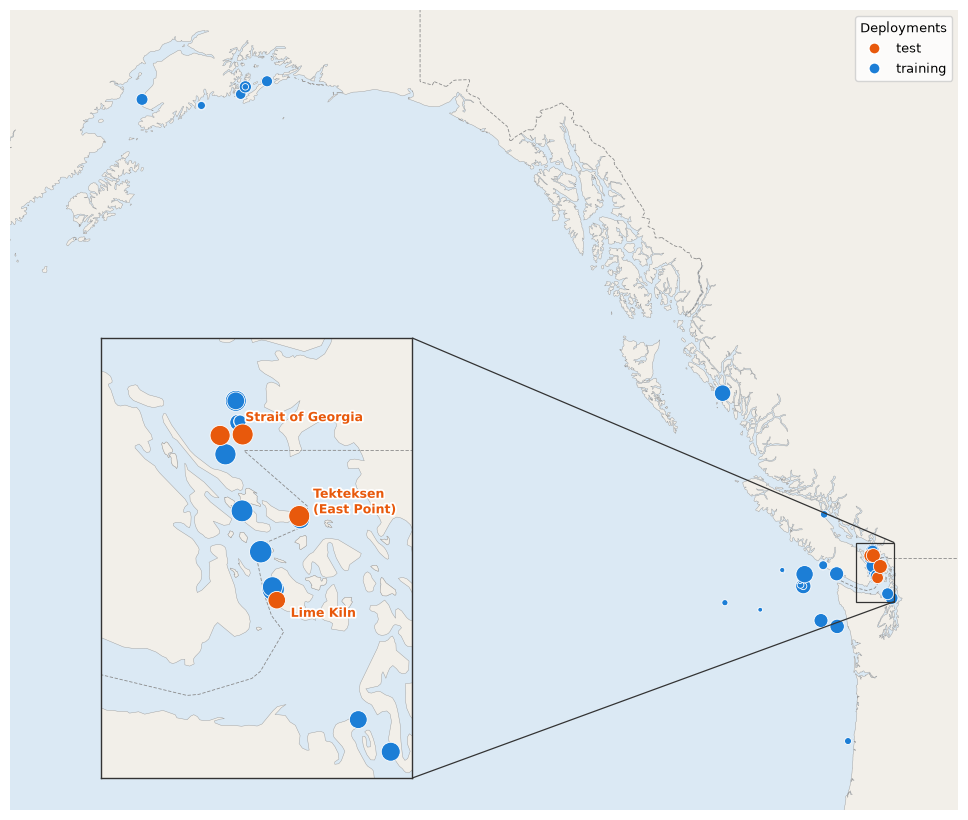

In [8]:
fig, ax = plt.subplots(figsize=(11, 8))
draw_basemap(ax, MAIN_EXTENT)
draw_deployments(ax, deployments, size_scale=4)
ax.set_xticks([])  # image only: no ticks, labels or frame (set_axis_off would also drop the sea colour)
ax.set_yticks([])
ax.spines[:].set_visible(False)

# Salish Sea inset, in the open Pacific (lower left of the main map)
inset = ax.inset_axes([0.03, 0.04, 0.46, 0.55])
draw_basemap(inset, INSET_EXTENT)
draw_deployments(inset, deployments, size_scale=9)
inset.set_xticks([])
inset.set_yticks([])
for spine in inset.spines.values():
    spine.set_edgecolor("#333")
    spine.set_linewidth(1.0)
mark_inset(ax, inset, loc1=1, loc2=4, fc="none", ec="#333", lw=0.9, zorder=5)
TEST_LABELS = {  # dataset -> (label, text offset in points)
    "DORI VENUS (Strait of Georgia)": ("Strait of Georgia", (10, 10)),
    "LimeKiln": ("Lime Kiln", (10, -12)),
    "Tekteksen": ("Tekteksen\n(East Point)", (10, 2)),
}
for dataset, (label, offset) in TEST_LABELS.items():
    site = deployments[deployments.Dataset == dataset]
    inset.annotate(label, (site.lon.mean(), site.lat.mean()), xytext=offset, textcoords="offset points",
                   fontsize=9, fontweight="bold", color=COLORS["test"], zorder=6,
                   path_effects=[patheffects.withStroke(linewidth=2.5, foreground="white")])

handles = [Line2D([], [], marker="o", ls="", markersize=8, markerfacecolor=c, markeredgecolor="white", label=k)
           for k, c in COLORS.items()]
ax.legend(handles=handles, loc="upper right", frameon=True, fontsize=9, title="Deployments", title_fontsize=9)
fig.subplots_adjust(left=0, right=1, bottom=0, top=1)
plt.show()


In [9]:
# optional: save for the paper
# fig.savefig("deployment_map_inset.png", dpi=300, bbox_inches="tight"); fig.savefig("deployment_map_inset.pdf", bbox_inches="tight")

In [10]:
# optional: standalone html to share / screenshot
# full_map.save("deployment_map.html"); salish_map.save("deployment_map_salish_sea.html")